# Machine Learning

## Week 1

### Day 1

Feature Engineering — Turning Messy Data into ML-Ready Gold


```
Dataset: Real Estate data.
Problem Statement: Predict price/sqft
```



In [3]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/Anandhu114/Bengaluru-House-Data/main/Bengaluru_House_Data.csv"
df  = pd.read_csv(url)

print(f"Shape: {df.shape}")
print(f"\nFirst 5 rows:")
print(df.head())
print(f"\nData types:")
print(df.dtypes)
print(f"\nMissing values:")
print(df.isnull().sum())
print(f"\nSample 'total_sqft' values:")
print(df["total_sqft"].sample(15, random_state=42).values)
# print(df["total_sqft"].value_counts())

# print(df.head(5))
print(df["total_sqft"].tail(15))

Shape: (13320, 9)

First 5 rows:
              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  

Data types:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price

#### Clean the Messy Columns

In [4]:
# ── FIX 1: Extract BHK number from "size" column ────────────
# "3 BHK" → 3,   "4 Bedroom" → 4
print(df["size"].value_counts())
print("Before:", df["size"].value_counts().head(5).to_dict())
df["bhk"] = df["size"].str.extract(r"(\d+)").astype(float)
print("After:", df["bhk"].value_counts().head(5).to_dict())

# ── FIX 2: Parse total_sqft — handles ranges and units ───────
import re

def parse_sqft(value):
    try:
        value = str(value).strip()
        if "-" in value:                        # "1000-1500" → 1250
            parts = value.split("-")
            return (float(parts[0]) + float(parts[1])) / 2
        if "sq. meter" in value.lower():        # convert sq.m to sqft
            num = float(re.match(r"[\d.]+", value).group())  # grab leading number only
            return num * 10.764                 # "34.46Sq. Meter" → 370.9 sqft
        if "sq. yards" in value.lower():        # convert sq.yards to sqft
            num = float(re.match(r"[\d.]+", value).group())  # grab leading number only
            return num * 9.0
        return float(value)
    except (ValueError, AttributeError):
        return np.nan

df["sqft"] = df["total_sqft"].apply(parse_sqft)
print(f"\nSqft after parsing:")
print(f"  Min: {df['sqft'].min():.0f}")
print(f"  Max: {df['sqft'].max():.0f}")
print(f"  Missing: {df['sqft'].isnull().sum()}")

print(df[df["sqft"].isnull()]["total_sqft"].unique())

# ── FIX 3: Handle missing values ─────────────────────────────
# location included — one row has a missing location, and it would
# crash the target-encoding lambda in Cell 2 with KeyError: nan
df.dropna(subset=["sqft", "bath", "bhk", "location"], inplace=True)
df["balcony"] = df["balcony"].fillna(df["balcony"].median())
print(f"\nAfter cleaning: {len(df):,} rows remain")

size
2 BHK         5199
3 BHK         4310
4 Bedroom      826
4 BHK          591
3 Bedroom      547
1 BHK          538
2 Bedroom      329
5 Bedroom      297
6 Bedroom      191
1 Bedroom      105
8 Bedroom       84
7 Bedroom       83
5 BHK           59
9 Bedroom       46
6 BHK           30
7 BHK           17
1 RK            13
10 Bedroom      12
9 BHK            8
8 BHK            5
11 BHK           2
10 BHK           2
11 Bedroom       2
27 BHK           1
19 BHK           1
43 Bedroom       1
16 BHK           1
14 BHK           1
12 Bedroom       1
13 BHK           1
18 Bedroom       1
Name: count, dtype: int64
Before: {'2 BHK': 5199, '3 BHK': 4310, '4 Bedroom': 826, '4 BHK': 591, '3 Bedroom': 547}
After: {2.0: 5528, 3.0: 4857, 4.0: 1417, 1.0: 656, 5.0: 356}

Sqft after parsing:
  Min: 1
  Max: 52272
  Missing: 14
['4125Perch' '5.31Acres' '30Acres' '3Cents' '2.09Acres' '24Guntha'
 '1500Cents' '2Acres' '15Acres' '1.26Acres' '1Grounds' '1.25Acres'
 '38Guntha' '6Acres']

After cleaning: 

In [5]:
# ── CREATE TARGET FIRST ───────────────────────────────────────
df["price_per_sqft"] = (df["price"] * 100000 / df["sqft"]).round(2)
print(f"Target created. Range: ₹{df['price_per_sqft'].min():.0f} to ₹{df['price_per_sqft'].max():.0f}/sqft")

# ── ONE-HOT ENCODING — area_type (4 unique values) ────────────
print(f"\narea_type values: {df['area_type'].value_counts().to_dict()}")
area_dummies = pd.get_dummies(df["area_type"], drop_first=True, dtype=int)
print(f"One-hot created {area_dummies.shape[1]} new columns:")
print(area_dummies.head(4))
print("drop_first=True avoids multicollinearity (a row with zeros in every dummy column belongs to the dropped category)")

# ── TARGET ENCODING — location (1300+ unique values) ──────────
n_unique = df["location"].nunique()
print(f"\nLocation has {n_unique} unique values")
print("One-hot would create 1,297 columns — too many!")
print("\nSolution: TARGET ENCODING — replace with mean price_per_sqft")

# Simplify first: < 10 occurrences → "Other"
loc_counts          = df["location"].value_counts()
df["loc_simple"]    = df["location"].apply(lambda x: x if loc_counts[x] >= 10 else "Other")
loc_avg_price       = df.groupby("loc_simple")["price_per_sqft"].mean()
df["loc_encoded"]   = df["loc_simple"].map(loc_avg_price)

print(f"\nTop 5 location encodings:")
for loc in ["Whitefield","Koramangala","Indiranagar","Other"]:
    if loc in loc_avg_price.index:
        print(f"  {loc:<20}: ₹{loc_avg_price[loc]:,.0f}/sqft")

Target created. Range: ₹268 to ₹12000000/sqft

area_type values: {'Super built-up  Area': 8740, 'Built-up  Area': 2409, 'Plot  Area': 1996, 'Carpet  Area': 87}
One-hot created 3 new columns:
   Carpet  Area  Plot  Area  Super built-up  Area
0             0           0                     1
1             0           1                     0
2             0           0                     0
3             0           0                     1
drop_first=True avoids multicollinearity (a row with zeros in every dummy column belongs to the dropped category)

Location has 1299 unique values
One-hot would create 1,297 columns — too many!

Solution: TARGET ENCODING — replace with mean price_per_sqft

Top 5 location encodings:
  Whitefield          : ₹6,880/sqft
  Koramangala         : ₹10,523/sqft
  Other               : ₹9,400/sqft


#### Scaling

In [6]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Prepare feature sample for demonstration
df_clean = df.dropna(subset=["sqft","bath","bhk","loc_encoded"]).copy()
features = df_clean[["sqft","bath","bhk","loc_encoded"]].head(8)

print("BEFORE SCALING — notice different ranges:")
print(features.describe().loc[["mean","std","min","max"]].round(2))

# ── STANDARDSCALER (Z-score) ─────────────────────────────────
standard = StandardScaler()
scaled_s = pd.DataFrame(standard.fit_transform(features),
                        columns=features.columns)
print("\nAFTER StandardScaler:")
print(scaled_s.describe().loc[["mean","std"]].round(4))
print("→ All features: mean≈0, std≈1")

# ── MINMAXSCALER ─────────────────────────────────────────────
minmax  = MinMaxScaler()
scaled_m = pd.DataFrame(minmax.fit_transform(features),
                        columns=features.columns)
print("\nAFTER MinMaxScaler:")
print(scaled_m.describe().loc[["mean","std","min","max"]].round(4))
print("→ All features: range [0, 1]")

print("""
WHICH TO USE?
  StandardScaler → Linear Regression, Logistic Reg, SVM, Neural Nets
  MinMaxScaler   → Neural nets (sigmoid output), image pixels [0,255]
  No scaling     → Decision Trees, Random Forest, XGBoost (tree-based)
""")

BEFORE SCALING — notice different ranges:
         sqft  bath   bhk  loc_encoded
mean  1877.38   3.0  3.00      6760.48
std    864.26   1.2  0.93      3190.42
min   1056.00   2.0  2.00      3882.66
max   3300.00   5.0  4.00     13989.07

AFTER StandardScaler:
       sqft   bath    bhk  loc_encoded
mean  0.000  0.000  0.000        0.000
std   1.069  1.069  1.069        1.069
→ All features: mean≈0, std≈1

AFTER MinMaxScaler:
        sqft    bath     bhk  loc_encoded
mean  0.3660  0.3333  0.5000       0.2848
std   0.3851  0.3984  0.4629       0.3157
min   0.0000  0.0000  0.0000       0.0000
max   1.0000  1.0000  1.0000       1.0000
→ All features: range [0, 1]

WHICH TO USE?
  StandardScaler → Linear Regression, Logistic Reg, SVM, Neural Nets
  MinMaxScaler   → Neural nets (sigmoid output), image pixels [0,255]
  No scaling     → Decision Trees, Random Forest, XGBoost (tree-based)



#### Outlier Removal + Data Leakage Warning

In [7]:
# Remove outliers from price_per_sqft using IQR
# (IQR preferred — price data is right-skewed, not normal)
Q1  = df_clean["price_per_sqft"].quantile(0.25)
Q3  = df_clean["price_per_sqft"].quantile(0.75)
IQR = Q3 - Q1

mask        = (df_clean["price_per_sqft"] >= Q1 - 1.5*IQR) & \
              (df_clean["price_per_sqft"] <= Q3 + 1.5*IQR)
df_model    = df_clean[mask].copy()

print(f"Before outlier removal: {len(df_clean):,} rows")
print(f"After  outlier removal: {len(df_model):,} rows")
print(f"Removed: {len(df_clean)-len(df_model):,} rows ({(len(df_clean)-len(df_model))/len(df_clean)*100:.1f}%)")

# Also remove logically impossible values
df_model = df_model[df_model["sqft"] > 300]          # min realistic size
df_model = df_model[df_model["bath"] <= df_model["bhk"] + 2]  # too many bathrooms
df_model = df_model[df_model["price_per_sqft"] > 100] # data entry error
print(f"After logic filter:     {len(df_model):,} rows")

print("""
DATA LEAKAGE — The #1 ML Mistake
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

ANALOGY: A student peeks at the exam before revision.
Scores 100% — but learns nothing. Fails real exams.

RULE: SPLIT YOUR DATA BEFORE ANYTHING ELSE.
Scaler must ONLY see training data statistics.

We fix this tomorrow using: sklearn Pipeline
Pipeline fits the scaler on X_train automatically.
""")

Before outlier removal: 13,232 rows
After  outlier removal: 11,970 rows
Removed: 1,262 rows (9.5%)
After logic filter:     11,960 rows

DATA LEAKAGE — The #1 ML Mistake
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

ANALOGY: A student peeks at the exam before revision.
Scores 100% — but learns nothing. Fails real exams.

RULE: SPLIT YOUR DATA BEFORE ANYTHING ELSE.
Scaler must ONLY see training data statistics.

We fix this tomorrow using: sklearn Pipeline
Pipeline fits the scaler on X_train automatically.



### Day 2

#### Simple Linear Regression

In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings; warnings.filterwarnings("ignore")

# Use the cleaned data from yesterday
url = "https://raw.githubusercontent.com/Anandhu114/Bengaluru-House-Data/main/Bengaluru_House_Data.csv"
df  = pd.read_csv(url)
df["bhk"]  = df["size"].str.extract(r"(\d+)").astype(float)

import re
def parse_sqft(v):
    try:
        v = str(v).strip()
        if "-" in v:
            p = v.split("-"); return (float(p[0])+float(p[1]))/2
        if "sq. meter" in v.lower():
            return float(re.match(r"[\d.]+", v).group())*10.764
        return float(v)
    except (ValueError, AttributeError): return np.nan

df["sqft"] = df["total_sqft"].apply(parse_sqft)
df = df.dropna(subset=["sqft","bath","bhk","price","location"])  # location needed for Cell 3 encoding
df["price_per_sqft"] = df["price"]*100000/df["sqft"]
Q1,Q3  = df["price_per_sqft"].quantile([0.25,0.75])
IQR    = Q3-Q1
df     = df[(df["price_per_sqft"]>=Q1-1.5*IQR)&(df["price_per_sqft"]<=Q3+1.5*IQR)]
df     = df[(df["sqft"]>300)&(df["bath"]<=df["bhk"]+2)]
print(f"Working dataset: {len(df):,} houses")

# SIMPLE LINEAR REGRESSION — one feature only
X = df[["sqft"]]         # 2D required for sklearn — double brackets!
y = df["price_per_sqft"]

model = LinearRegression()
model.fit(X, y)           # THIS LINE = the model learns

print(f"\nModel learned:")
print(f"  Slope:     {model.coef_[0]:.6f}  (₹ per extra sqft)")
print(f"  Intercept: {model.intercept_:.2f}")
print(f"\nPredictions:")
for sqft in [800, 1200, 1800, 2500]:
    pred = model.predict([[sqft]])[0]
    print(f"  {sqft} sqft → ₹{pred:,.0f}/sqft")

Working dataset: 11,941 houses

Model learned:
  Slope:     0.186337  (₹ per extra sqft)
  Intercept: 5290.16

Predictions:
  800 sqft → ₹5,439/sqft
  1200 sqft → ₹5,514/sqft
  1800 sqft → ₹5,626/sqft
  2500 sqft → ₹5,756/sqft


#### Train-Test Split + Evaluation Metrics

Training:   9,552 houses
Testing:    2,389  houses

  SIMPLE REGRESSION RESULTS
  MAE:  ₹   1,482  ← avg error per prediction
  RMSE: ₹   1,922  ← penalises large errors more
  R²:      0.0212  ← 2.1% of variance explained


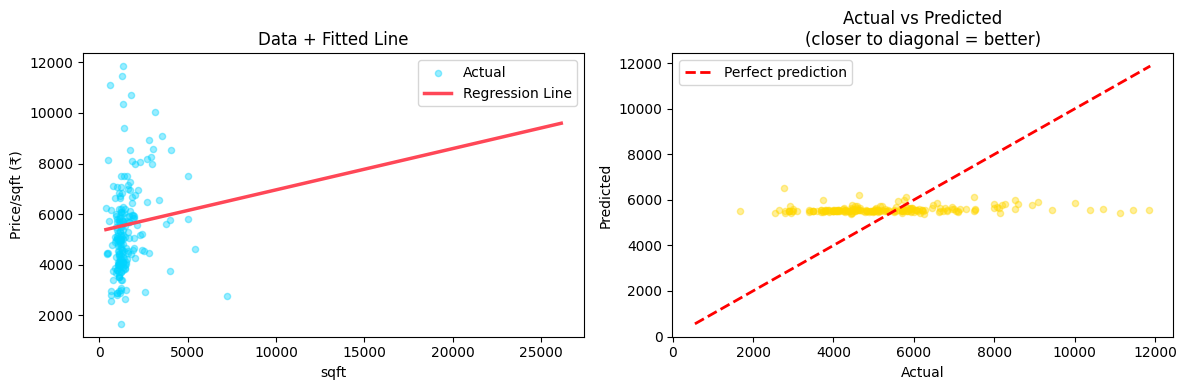

In [9]:
# TRAIN-TEST SPLIT — the right way
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Training:   {len(X_train):,} houses")
print(f"Testing:    {len(X_test):,}  houses")

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# EVALUATION
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print(f"\n{'='*40}")
print(f"  SIMPLE REGRESSION RESULTS")
print(f"{'='*40}")
print(f"  MAE:  ₹{mae:>8,.0f}  ← avg error per prediction")
print(f"  RMSE: ₹{rmse:>8,.0f}  ← penalises large errors more")
print(f"  R²:    {r2:>8.4f}  ← {r2*100:.1f}% of variance explained")
print(f"{'='*40}")

# Actual vs Predicted plot
plt.figure(figsize=(12, 4))
plt.subplot(1,2,1)
sample = np.random.choice(len(X_test), 200, replace=False)
plt.scatter(X_test.iloc[sample], y_test.iloc[sample],
            alpha=0.4, color="#00d4ff", s=20, label="Actual")
x_line = np.linspace(X_test.min().iloc[0], X_test.max().iloc[0], 100)
plt.plot(x_line, model.predict(x_line.reshape(-1,1)),
         color="#ff4757", lw=2.5, label="Regression Line")
plt.xlabel("sqft"); plt.ylabel("Price/sqft (₹)"); plt.legend()
plt.title("Data + Fitted Line")

plt.subplot(1,2,2)
plt.scatter(y_test.iloc[sample], y_pred[sample], alpha=0.4, color="#ffd700", s=20)
lim = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lim, lim, "r--", lw=2, label="Perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.legend()
plt.title("Actual vs Predicted\n(closer to diagonal = better)")
plt.tight_layout(); plt.show()

#### Multiple Regression (Multiple Features)+ Pipeline

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Target encode location (simplified)
loc_counts      = df["location"].value_counts()
df["loc_simple"]= df["location"].apply(lambda x: x if loc_counts[x]>=10 else "Other")
df["loc_enc"]   = df["loc_simple"].map(df.groupby("loc_simple")["price_per_sqft"].mean())

# Multiple features
features = ["sqft","bhk","bath","loc_enc"]
df_m     = df[features + ["price_per_sqft"]].dropna()
X_multi  = df_m[features]
y_multi  = df_m["price_per_sqft"]

X_tr, X_te, y_tr, y_te = train_test_split(X_multi, y_multi,
                                           test_size=0.2, random_state=42)

# PIPELINE — the professional way (prevents leakage!)
pipeline = Pipeline([
    ("scaler", StandardScaler()),     # Step 1: scale (fit on train only!)
    ("model",  LinearRegression())    # Step 2: train
])
pipeline.fit(X_tr, y_tr)
y_pred_m = pipeline.predict(X_te)

mae_m  = mean_absolute_error(y_te, y_pred_m)
rmse_m = np.sqrt(mean_squared_error(y_te, y_pred_m))
r2_m   = r2_score(y_te, y_pred_m)

print(f"MULTIPLE REGRESSION RESULTS:")
print(f"  Features used: {features}")
print(f"  MAE:  ₹{mae_m:,.0f}")
print(f"  RMSE: ₹{rmse_m:,.0f}")
print(f"  R²:    {r2_m:.4f} ({r2_m*100:.1f}% variance explained)")
print(f"\nImprovement from adding location: R² {r2:.4f} → {r2_m:.4f}")
print(f"Feature engineering mattered more than model choice!")

MULTIPLE REGRESSION RESULTS:
  Features used: ['sqft', 'bhk', 'bath', 'loc_enc']
  MAE:  ₹1,189
  RMSE: ₹1,622
  R²:    0.3029 (30.3% variance explained)

Improvement from adding location: R² 0.0212 → 0.3029
Feature engineering mattered more than model choice!


### Day 3

#### Ridge + Lasso Regularization

In [11]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score

print("REGULARIZATION — Preventing Overfitting")
print("="*45)
print("""
ANALOGY: A student who memorises textbook word-for-word.
Aces practice tests. Fails real exam (new questions).
= OVERFITTING

RIDGE (L2): adds penalty for large weights → shrinks all weights
LASSO (L1): can shrink weights to EXACTLY ZERO → removes features!

α (alpha) = regularization strength
  α = 0    → plain linear regression (no penalty)
  α = 100  → strong penalty, weights shrink a lot
""")

results = []
for name, model_cls, alpha in [
    ("Linear (no reg)",  LinearRegression, None),
    ("Ridge  α=1",       Ridge,            1),
    ("Ridge  α=100",     Ridge,            100),
    ("Lasso  α=1",       Lasso,            1),
    ("Lasso  α=100",     Lasso,            100),
]:
    if alpha is None:
        m = Pipeline([("sc", StandardScaler()), ("m", model_cls())])
    else:
        m = Pipeline([("sc", StandardScaler()), ("m", model_cls(alpha=alpha, max_iter=5000))])
    cv_r2 = cross_val_score(m, X_multi, y_multi, cv=5, scoring="r2").mean()
    results.append((name, cv_r2))
    print(f"  {name:<20}: CV R² = {cv_r2:.4f}")

best = max(results, key=lambda x: x[1])
print(f"\nBest model: {best[0]} (R² = {best[1]:.4f})")

REGULARIZATION — Preventing Overfitting

ANALOGY: A student who memorises textbook word-for-word.
Aces practice tests. Fails real exam (new questions).
= OVERFITTING

RIDGE (L2): adds penalty for large weights → shrinks all weights
LASSO (L1): can shrink weights to EXACTLY ZERO → removes features!

α (alpha) = regularization strength
  α = 0    → plain linear regression (no penalty)
  α = 100  → strong penalty, weights shrink a lot

  Linear (no reg)     : CV R² = 0.3077
  Ridge  α=1          : CV R² = 0.3077
  Ridge  α=100        : CV R² = 0.3077
  Lasso  α=1          : CV R² = 0.3077
  Lasso  α=100        : CV R² = 0.2995

Best model: Ridge  α=100 (R² = 0.3077)


##### Confusion Matrix

THE CONFUSION MATRIX — 4 outcomes


```
                Predicted NO    Predicted YES
Actual NO:      TN (correct)    FP (false alarm)
Actual YES:     FN (MISSED!)    TP (correct)

```



For medical diagnosis:
  FN = told you're healthy when diabetic = DANGEROUS!
  
  FP = told you might have diabetes when healthy = extra test (annoying but safe)

→ For medical: we want HIGH RECALL (catch all true diabetics)

→ We ACCEPT some false alarms to avoid missing real cases

METRICS:
  Accuracy  = (TP+TN) / total       ← misleading for imbalanced!

  Precision = TP / (TP+FP)          ← "when I say YES, how often right?"

  Recall    = TP / (TP+FN)          ← "of all actual YES, how many caught?"

  F1        = 2 × P × R / (P+R)    ← balance of both

  AUC-ROC   = overall discrimination power (0.5=random, 1.0=perfect)

#### Classification — Logistic Regression + Evaluation Metrics

##### Load the new dataset

In [12]:
import pandas as pd, numpy as np

url  = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df   = pd.read_csv(url)
print(f"Shape: {df.shape}")
print(df.head())
print(f"\nTarget distribution:")
print(df["Outcome"].value_counts())
print(f"Diabetic rate: {df['Outcome'].mean():.1%}")

Shape: (768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64
Diabetic rate: 34.9%


##### Clean Diabetes Data

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import warnings; warnings.filterwarnings("ignore")

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df  = pd.read_csv(url)

# PROBLEM: These medical values CANNOT be zero — biologically impossible!
# Glucose=0, BMI=0, BloodPressure=0 are MISSING VALUES disguised as zeros
medical_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print("Zero values (actually missing):")
for col in medical_cols:
    zeros = (df[col] == 0).sum()
    if zeros > 0:
        print(f"  {col:<20}: {zeros} zeros ({zeros/len(df)*100:.1f}%)")

# Replace 0 with median of non-zero values
for col in medical_cols:
    median_val = df[df[col] != 0][col].median()
    df[col]    = df[col].replace(0, median_val)

print(f"\nZeros replaced with column medians.")
print(f"Dataset: {df.shape[0]} patients, {df.shape[1]-1} features, 1 target")

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
feature_names = X.columns.tolist()
print(f"Features: {feature_names}")

Zero values (actually missing):
  Glucose             : 5 zeros (0.7%)
  BloodPressure       : 35 zeros (4.6%)
  SkinThickness       : 227 zeros (29.6%)
  Insulin             : 374 zeros (48.7%)
  BMI                 : 11 zeros (1.4%)

Zeros replaced with column medians.
Dataset: 768 patients, 8 features, 1 target
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


##### Logistic Regression

In [14]:
# Train-test split — stratify ensures same % diabetic in each split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} patients ({y_train.sum()} diabetic)")
print(f"Test:  {len(X_test)}  patients ({y_test.sum()}  diabetic)")

# Pipeline: scale → train (prevents leakage)
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model",  LogisticRegression(random_state=42, max_iter=1000))
])
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]  # probability of class 1

# Quick results
from sklearn.metrics import accuracy_score, precision_score as precision, recall_score as recall, f1_score
print(f"\nAccuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"\nPrecision: {precision(y_test, y_pred):.4f}")
print(f"\nRecall: {recall(y_test, y_pred):.4f}")
print(f"\nF1: {f1_score(y_test, y_pred):.4f}")
print(f"\nSample predictions:")
for i in range(5):
    print(f"  Patient {i+1}: prob={y_prob[i]:.2%} → predicted={'DIABETIC' if y_pred[i]==1 else 'HEALTHY'} | actual={'DIABETIC' if y_test.iloc[i]==1 else 'HEALTHY'}")

Train: 614 patients (214 diabetic)
Test:  154  patients (54  diabetic)

Accuracy: 0.7078

Precision: 0.6000

Recall: 0.5000

F1: 0.5455

Sample predictions:
  Patient 1: prob=60.97% → predicted=DIABETIC | actual=HEALTHY
  Patient 2: prob=11.84% → predicted=HEALTHY | actual=HEALTHY
  Patient 3: prob=29.35% → predicted=HEALTHY | actual=HEALTHY
  Patient 4: prob=25.08% → predicted=HEALTHY | actual=DIABETIC
  Patient 5: prob=3.32% → predicted=HEALTHY | actual=HEALTHY


##### Confusion Matrix + All Metrics

CONFUSION MATRIX:
  True Negatives  (Healthy → Healthy):     82  ✅
  False Positives (Healthy → Diabetic):    18  ⚠️  False alarm
  False Negatives (Diabetic → Healthy):    27  🔴 DANGEROUS!
  True Positives  (Diabetic → Diabetic):   27  ✅

METRICS:
  Accuracy:  0.7078
  Precision: 0.6000  (of predicted diabetic, % correct)
  Recall:    0.5000  (of actual diabetic, % caught)
  F1 Score:  0.5455  (harmonic mean of P and R)

  For medical screening → RECALL is most important!
  Missing a diabetic patient (FN=27) is far more dangerous
  than a false alarm (FP=18)


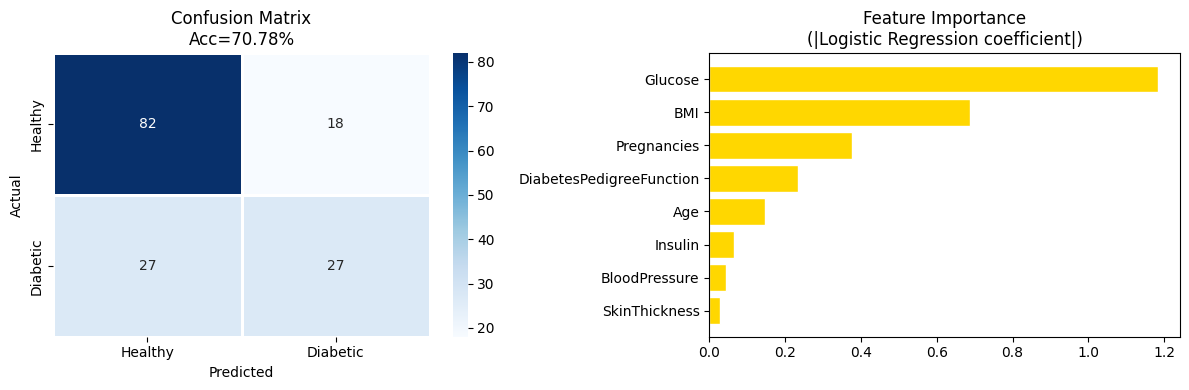

In [15]:
from sklearn.metrics import (confusion_matrix, classification_report,
                              precision_score, recall_score, f1_score)
import seaborn as sns, matplotlib.pyplot as plt

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print("CONFUSION MATRIX:")
print(f"  True Negatives  (Healthy → Healthy):    {tn:3d}  ✅")
print(f"  False Positives (Healthy → Diabetic):   {fp:3d}  ⚠️  False alarm")
print(f"  False Negatives (Diabetic → Healthy):   {fn:3d}  🔴 DANGEROUS!")
print(f"  True Positives  (Diabetic → Diabetic):  {tp:3d}  ✅")

print(f"\nMETRICS:")
print(f"  Accuracy:  {accuracy_score(y_test,y_pred):.4f}")
print(f"  Precision: {precision_score(y_test,y_pred):.4f}  (of predicted diabetic, % correct)")
print(f"  Recall:    {recall_score(y_test,y_pred):.4f}  (of actual diabetic, % caught)")
print(f"  F1 Score:  {f1_score(y_test,y_pred):.4f}  (harmonic mean of P and R)")
print(f"\n  For medical screening → RECALL is most important!")
print(f"  Missing a diabetic patient (FN={fn}) is far more dangerous")
print(f"  than a false alarm (FP={fp})")

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Healthy","Diabetic"], yticklabels=["Healthy","Diabetic"],
            linewidths=2, linecolor="white")
axes[0].set_title(f"Confusion Matrix\nAcc={accuracy_score(y_test,y_pred):.2%}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

# Feature importance (coefficients)
coefs = np.abs(lr.named_steps["model"].coef_[0])
order = np.argsort(coefs)
axes[1].barh([feature_names[i] for i in order], coefs[order],
             color="#ffd700", edgecolor="white")
axes[1].set_title("Feature Importance\n(|Logistic Regression coefficient|)")
plt.tight_layout(); plt.show()

### Day 4

#### ROC Curve + AUC

AUC-ROC Score: 0.8130

WHAT AUC MEANS:
  AUC = 0.81 means: if I pick one random diabetic patient
  and one random healthy patient, the model ranks the diabetic
  HIGHER than the healthy patient 81% of the time.

  AUC = 0.50  → random guessing (useless)
  AUC = 0.70  → fair
  AUC = 0.80  → good
  AUC = 0.90+ → excellent

THRESHOLD EFFECT:
 Threshold   Recall  Precision   False Alarms
----------------------------------------------
       0.3    0.796      0.597             29
       0.4    0.648      0.614             22
       0.5    0.500      0.600             18
       0.6    0.463      0.641             14
       0.7    0.370      0.714              8

Lower threshold → catch MORE diabetics → more false alarms


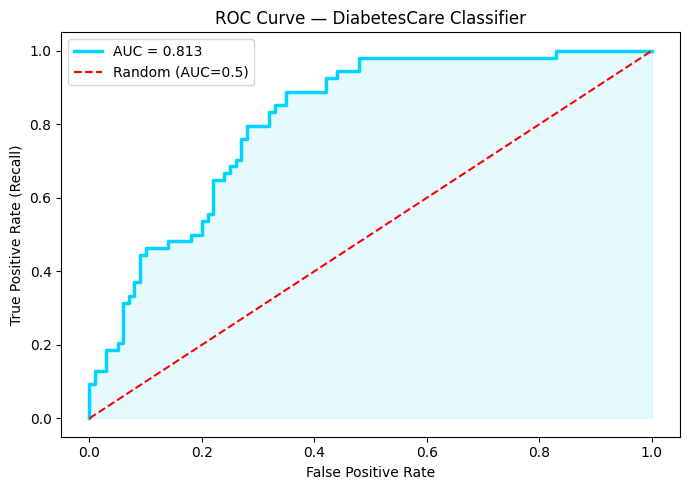

In [16]:
from sklearn.metrics import roc_curve, roc_auc_score, recall_score, precision_score, confusion_matrix

auc = roc_auc_score(y_test, y_prob)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

print(f"AUC-ROC Score: {auc:.4f}")
print(f"""
WHAT AUC MEANS:
  AUC = {auc:.2f} means: if I pick one random diabetic patient
  and one random healthy patient, the model ranks the diabetic
  HIGHER than the healthy patient {auc*100:.0f}% of the time.

  AUC = 0.50  → random guessing (useless)
  AUC = 0.70  → fair
  AUC = 0.80  → good
  AUC = 0.90+ → excellent
""")

# Threshold effect — show how changing threshold affects recall
print("THRESHOLD EFFECT:")
print(f"{'Threshold':>10} {'Recall':>8} {'Precision':>10} {'False Alarms':>14}")
print("-" * 46)
for thresh in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_t = (y_prob >= thresh).astype(int)
    r   = recall_score(y_test, y_t, zero_division=0)
    p   = precision_score(y_test, y_t, zero_division=0)
    fp_t= confusion_matrix(y_test, y_t).ravel()[1]
    #fp_t= confusion_matrix(y_test, y_t).ravel()
    #print("TYPE", type(confusion_matrix(y_test, y_t).ravel()))
    #print("Test Print", confusion_matrix(y_test, y_t).ravel())
    print(f"{thresh:>10.1f} {r:>8.3f} {p:>10.3f} {fp_t:>14}")
print("\nLower threshold → catch MORE diabetics → more false alarms")

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color="#00d4ff", lw=2.5, label=f"AUC = {auc:.3f}")
plt.fill_between(fpr, tpr, alpha=0.1, color="#00d4ff")
plt.plot([0,1],[0,1],"r--", lw=1.5, label="Random (AUC=0.5)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — DiabetesCare Classifier"); plt.legend()
plt.tight_layout(); plt.show()

#### Decision Trees + Cross-Validation

Decision Tree (depth=4): Acc=0.7857, AUC=0.7887


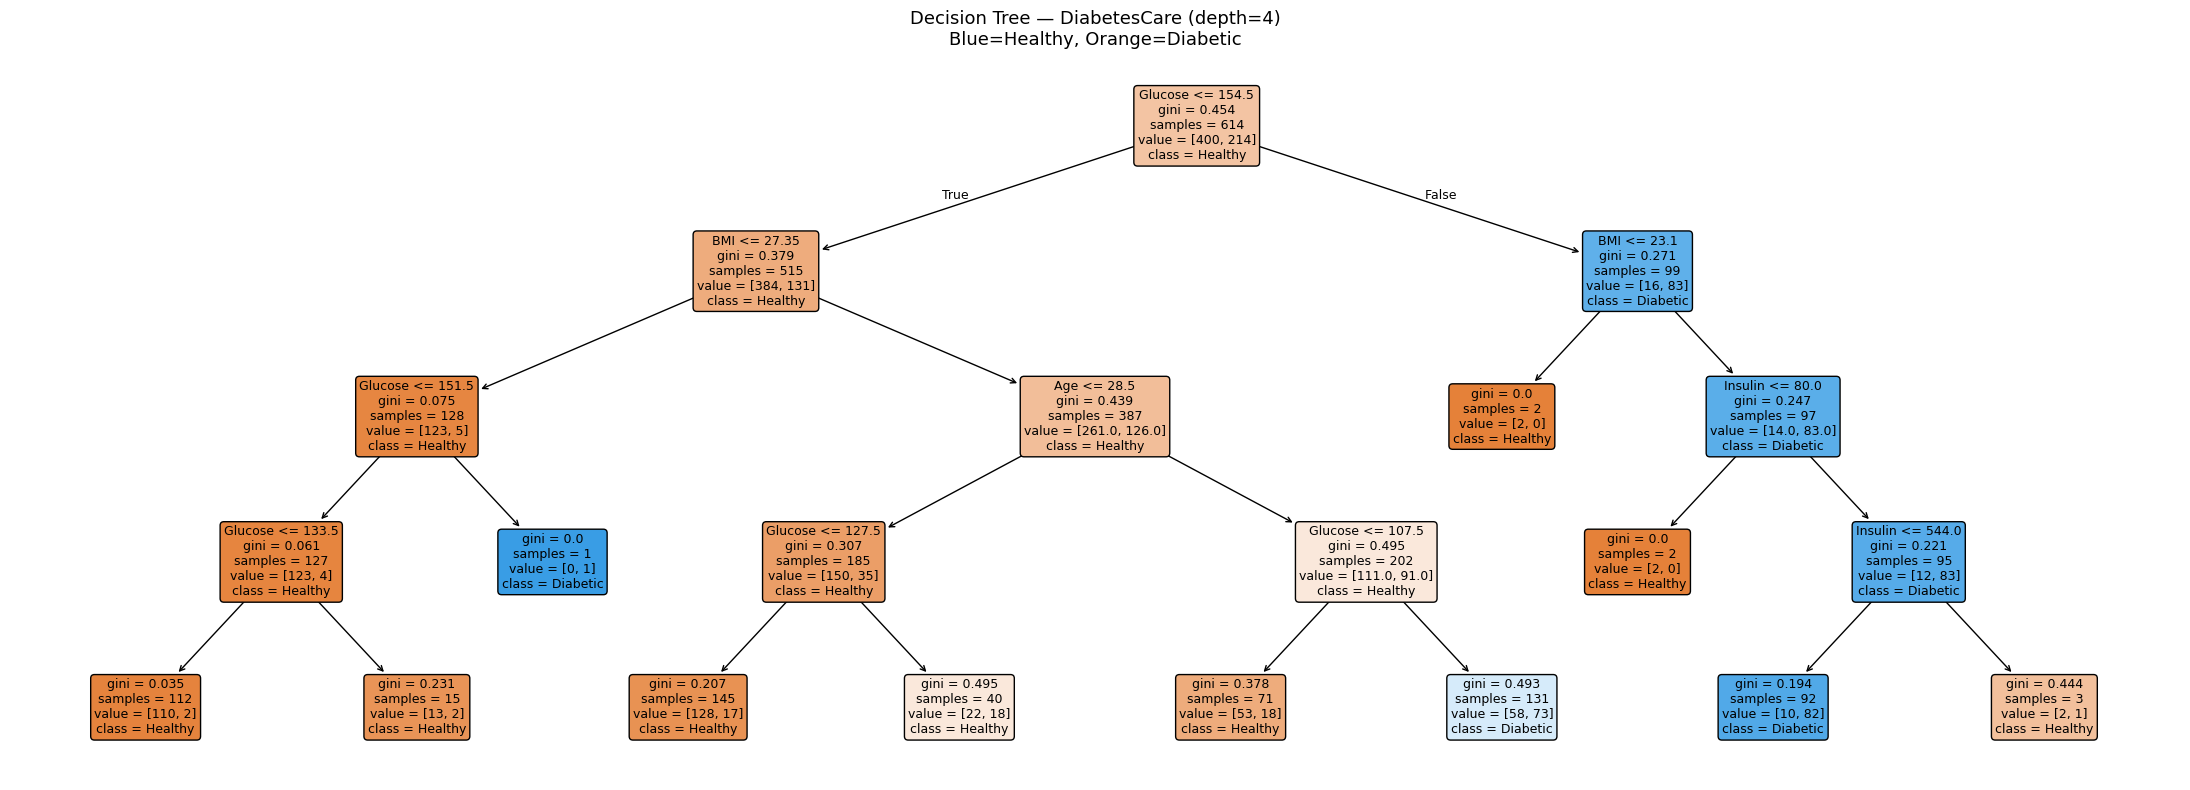


Tree rules (text):
|--- Glucose <= 154.50
|   |--- BMI <= 27.35
|   |   |--- Glucose <= 151.50
|   |   |   |--- Glucose <= 133.50
|   |   |   |   |--- class: 0
|   |   |   |--- Glucose >  133.50
|   |   |   |   |--- class: 0
|   |   |--- Glucose >  151.50
|   |   |   |--- class: 1
|   |--- BMI >  27.35
|   |   |--- Age <= 28.50
|   |   |   |--- Glucose <= 127.50
|   |   |   |   |--- class: 0
|   |   |   |--- Glucose >  127.50
|   |   |   |   |--- class: 0
|   |   |--- Age >  28.50
|   |   |   |--- Glucose <= 107.50
|   |   |   |   |--- class: 0
|   |   |   |--- Glucose >  107.50
|   |   |   |   |--- class: 1
|--- Glucose >  154.50
|   |--- BMI <= 23.10
|   |   |--- class: 0
|   |--- BMI >  23.10
|   |   |--- Insulin <= 80.00
|   |   |   |--- class: 0
|   |   |--- Insulin >  80.00
|   |   |   |--- Insulin <= 544.00
|   |   |   |   |--- class: 1
|   |   |   |--- Insulin >  544.00
|   |   |   |   |--- class: 0

Decision Tree (depth=4): Acc=0.7532, Recall=0.5370, AUC=0.8080


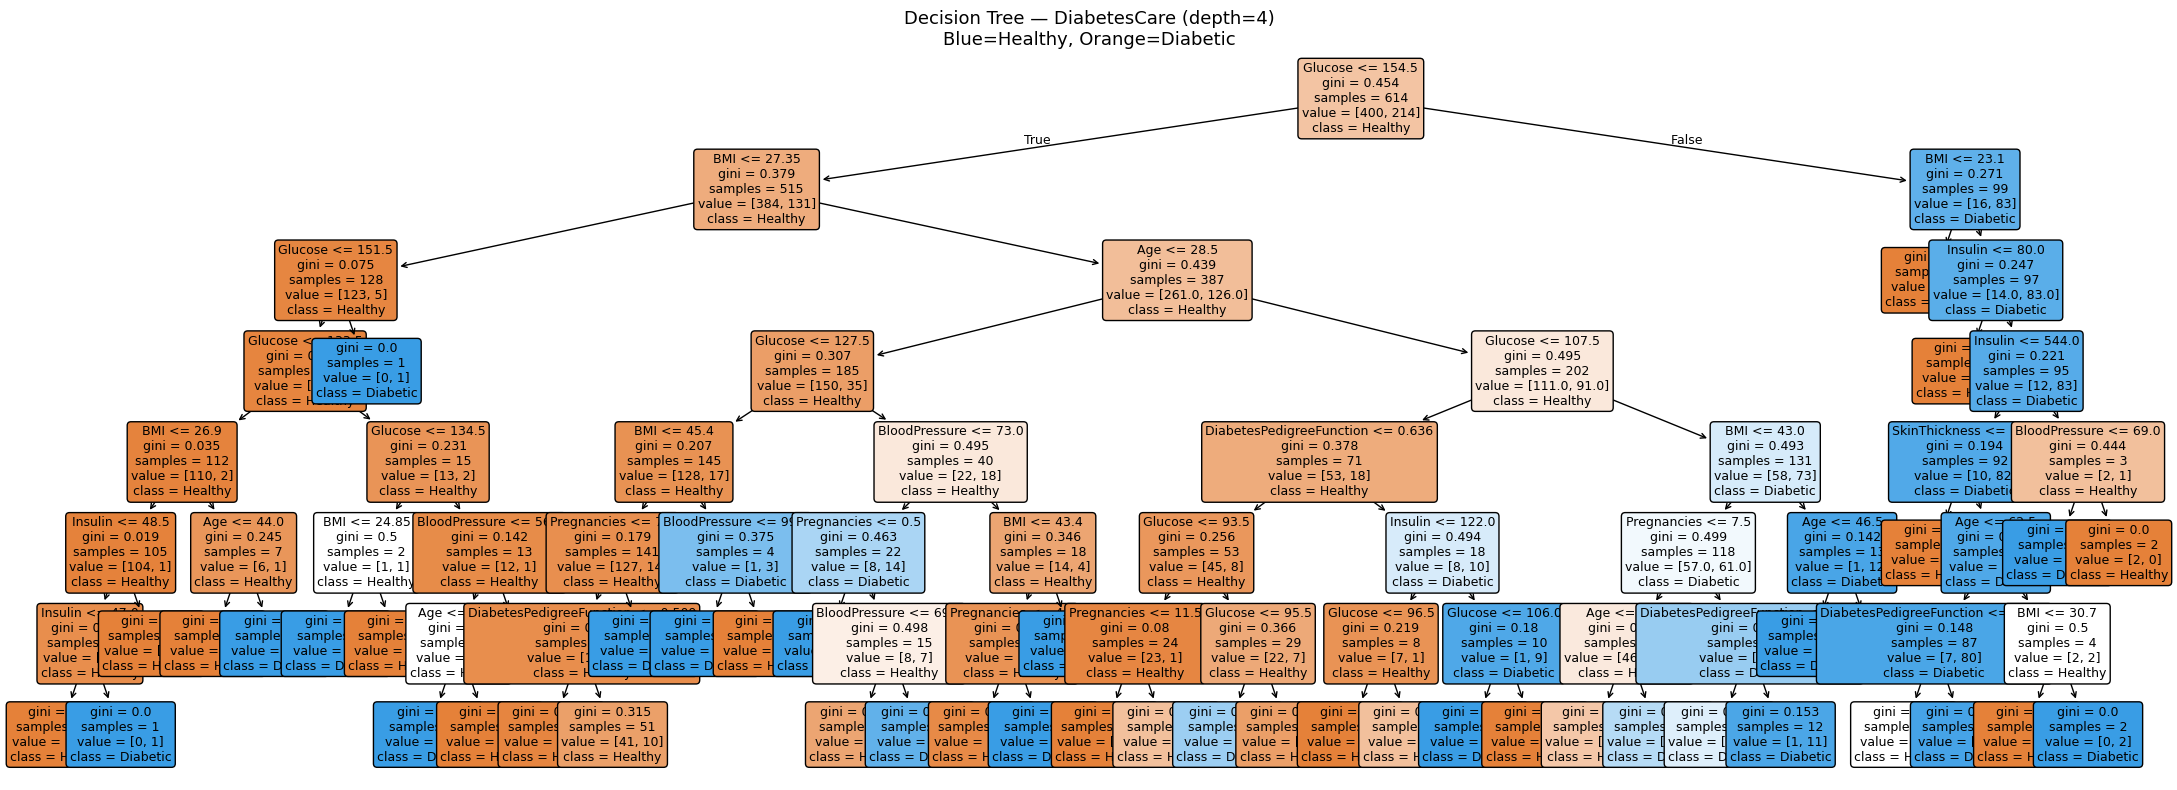


Tree rules (text):
|--- Glucose <= 154.50
|   |--- BMI <= 27.35
|   |   |--- Glucose <= 151.50
|   |   |   |--- Glucose <= 133.50
|   |   |   |   |--- BMI <= 26.90
|   |   |   |   |   |--- Insulin <= 48.50
|   |   |   |   |   |   |--- Insulin <= 47.00
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- Insulin >  47.00
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- Insulin >  48.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- BMI >  26.90
|   |   |   |   |   |--- Age <= 44.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- Age >  44.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |--- Glucose >  133.50
|   |   |   |   |--- Glucose <= 134.50
|   |   |   |   |   |--- BMI <= 24.85
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- BMI >  24.85
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- Glucose >  134.50
|   |   |   |   |   |--- BloodPressure <= 56.00
|   |   |   |   |   |   |--- Age <= 42

In [17]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score
import warnings; warnings.filterwarnings("ignore")

# Load and prep (same as yesterday)
url   = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df    = pd.read_csv(url)
cols  = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
for c in cols: df[c] = df[c].replace(0, df[df[c]!=0][c].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train a shallow, interpretable tree
tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

acc = accuracy_score(y_test, tree.predict(X_test))
auc = roc_auc_score(y_test, tree.predict_proba(X_test)[:,1])
print(f"Decision Tree (depth=4): Acc={acc:.4f}, AUC={auc:.4f}")

# Visualise the tree
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(tree, feature_names=feature_names,
          class_names=["Healthy","Diabetic"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree — DiabetesCare (depth=4)\nBlue=Healthy, Orange=Diabetic", fontsize=13)
plt.tight_layout(); plt.show()

# Text version — easier to read
print("\nTree rules (text):")
print(export_text(tree, feature_names=feature_names))

# Train a shallow, interpretable tree
tree_optimized_depth = DecisionTreeClassifier(max_depth=7, random_state=42)
tree_optimized_depth.fit(X_train, y_train)

acc = accuracy_score(y_test, tree_optimized_depth.predict(X_test))
recall = recall_score(y_test, tree_optimized_depth.predict(X_test))
auc = roc_auc_score(y_test, tree_optimized_depth.predict_proba(X_test)[:,1])
print(f"Decision Tree (depth=4): Acc={acc:.4f}, Recall={recall:.4f}, AUC={auc:.4f}")

# Visualise the tree
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(tree_optimized_depth, feature_names=feature_names,
          class_names=["Healthy","Diabetic"],
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title("Decision Tree — DiabetesCare (depth=4)\nBlue=Healthy, Orange=Diabetic", fontsize=13)
plt.tight_layout(); plt.show()

# Text version — easier to read
print("\nTree rules (text):")
print(export_text(tree_optimized_depth, feature_names=feature_names))

####  Overfitting Demo

Best depth by test AUC: 7

depth=1:  Train=0.761, Test=0.695 ← UNDERFITTING
depth=7:  Train=0.879, Test=0.753 ← SWEET SPOT
depth=19: Train=1.000, Test=0.682 ← OVERFITTING


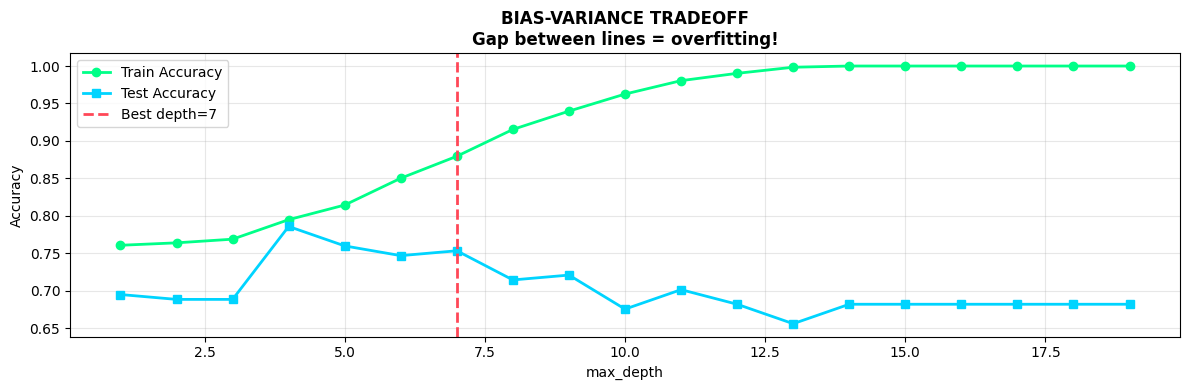


This chart IS the bias-variance tradeoff made visible.


In [18]:
# Show what happens as we increase depth
depths     = range(1, 20)
train_accs = []
test_accs  = []
test_aucs  = []

for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42)
    t.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, t.predict(X_train)))
    test_accs.append( accuracy_score(y_test,  t.predict(X_test)))
    test_aucs.append( roc_auc_score(y_test,   t.predict_proba(X_test)[:,1]))

best_depth = list(depths)[np.argmax(test_aucs)]
print(f"Best depth by test AUC: {best_depth}")
print(f"\ndepth=1:  Train={train_accs[0]:.3f}, Test={test_accs[0]:.3f} ← UNDERFITTING")
print(f"depth={best_depth}:  Train={train_accs[best_depth-1]:.3f}, Test={test_accs[best_depth-1]:.3f} ← SWEET SPOT")
print(f"depth=19: Train={train_accs[-1]:.3f}, Test={test_accs[-1]:.3f} ← OVERFITTING")

plt.figure(figsize=(12, 4))
plt.plot(depths, train_accs, "o-", color="#00ff88", lw=2, label="Train Accuracy")
plt.plot(depths, test_accs,  "s-", color="#00d4ff", lw=2, label="Test Accuracy")
plt.axvline(best_depth, color="#ff4757", ls="--", lw=2, label=f"Best depth={best_depth}")
plt.xlabel("max_depth"); plt.ylabel("Accuracy")
plt.title("BIAS-VARIANCE TRADEOFF\nGap between lines = overfitting!", fontweight="bold")
plt.legend(); plt.grid(True, alpha=0.3); plt.tight_layout(); plt.show()
print("\nThis chart IS the bias-variance tradeoff made visible.")

#### Cross-Validation

In [19]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": Pipeline([("sc",StandardScaler()),("m",LogisticRegression(max_iter=1000))]),
    "Decision Tree":       DecisionTreeClassifier(max_depth=best_depth, random_state=42),
}

print("5-FOLD STRATIFIED CROSS-VALIDATION")
print("="*55)
print(f"\n{'Model':<25} {'Mean AUC':>10} {'Std':>8} {'All 5 Folds'}")
print("-"*75)
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring="roc_auc")
    folds  = " ".join([f"{s:.3f}" for s in scores])
    print(f"{name:<25} {scores.mean():>10.4f} {scores.std():>8.4f}  [{folds}]")

# Show what cross_validate gives you (multiple metrics at once)
print("\nMultiple metrics for Logistic Regression:")
cv_results = cross_validate(
    models["Logistic Regression"], X, y, cv=skf,
    scoring=["accuracy","precision","recall","f1","roc_auc"],
    return_train_score=True
)
for metric in ["accuracy","recall","roc_auc"]:
    train_m = cv_results[f"train_{metric}"].mean()
    test_m  = cv_results[f"test_{metric}"].mean()
    gap     = train_m - test_m
    flag    = " ⚠️  Overfitting!" if gap > 0.05 else " ✅"
    print(f"  {metric:<12}: Train={train_m:.3f}, Val={test_m:.3f}, Gap={gap:.3f}{flag}")

5-FOLD STRATIFIED CROSS-VALIDATION

Model                       Mean AUC      Std All 5 Folds
---------------------------------------------------------------------------
Logistic Regression           0.8366   0.0204  [0.825 0.867 0.852 0.829 0.810]
Decision Tree                 0.7292   0.0579  [0.801 0.728 0.773 0.712 0.632]

Multiple metrics for Logistic Regression:
  accuracy    : Train=0.776, Val=0.773, Gap=0.002 ✅
  recall      : Train=0.572, Val=0.571, Gap=0.001 ✅
  roc_auc     : Train=0.846, Val=0.837, Gap=0.009 ✅


#### GridSearchCV - Pending for Day 5

In [20]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

print("GRIDSEARCHCV — Automated Hyperparameter Search")
print("="*50)
print("""
ANALOGY: Baking a cake — which combination is best?
  Temperature: 160°C, 180°C, 200°C
  Time: 25min, 30min, 35min
  → 9 combinations to try

GridSearchCV tries ALL combinations automatically.
""")

# Grid search on Decision Tree
param_grid = {
    "max_depth":         [3, 4, 5, 6, 7],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [1, 2, 5],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=skf,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=0
)
grid.fit(X, y)

print(f"Best hyperparameters:")
for param, val in grid.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest CV AUC: {grid.best_score_:.4f}")

# Evaluate best model on test set
best_tree = DecisionTreeClassifier(**grid.best_params_, random_state=42)
best_tree.fit(X_train, y_train)
final_auc = roc_auc_score(y_test, best_tree.predict_proba(X_test)[:,1])
print(f"Test AUC with tuned params: {final_auc:.4f}")
print(f"\nNote: test AUC may differ slightly from CV AUC — that's normal.")
print(f"CV AUC is your most reliable estimate of real-world performance.")

GRIDSEARCHCV — Automated Hyperparameter Search

ANALOGY: Baking a cake — which combination is best?
  Temperature: 160°C, 180°C, 200°C
  Time: 25min, 30min, 35min
  → 9 combinations to try

GridSearchCV tries ALL combinations automatically.

Best hyperparameters:
  max_depth: 3
  min_samples_leaf: 5
  min_samples_split: 2

Best CV AUC: 0.7885
Test AUC with tuned params: 0.7864

Note: test AUC may differ slightly from CV AUC — that's normal.
CV AUC is your most reliable estimate of real-world performance.


##Day 5

###Random Forest

Random Forest: Acc=0.7532, AUC=0.8094


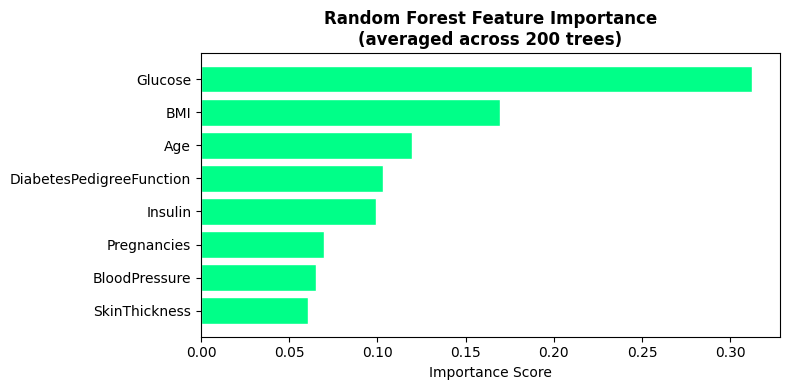

Which feature matters most for diabetes prediction?


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib.pyplot as plt
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

# Load diabetes (same as all week)
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for c in cols:
    df[c] = df[c].replace(0, df[df[c] != 0][c].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# RANDOM FOREST
rf = RandomForestClassifier(
    n_estimators=200,      # 200 trees
    max_depth=7,           # each tree limited
    max_features="sqrt",   # each split: √(n_features) features considered
    random_state=42,
    n_jobs=-1              # use all CPU cores
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(
    f"Random Forest: "
    f"Acc={accuracy_score(y_test, y_pred_rf):.4f}, "
    f"AUC={roc_auc_score(y_test, y_prob_rf):.4f}"
)

# Feature importance from 200 trees - more reliable than single tree
fi = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

fi = fi.sort_values("Importance", ascending=True)

plt.figure(figsize=(8, 4))
plt.barh(
    fi["Feature"],
    fi["Importance"],
    color="#00ff88",
    edgecolor="white"
)

plt.title(
    "Random Forest Feature Importance\n(averaged across 200 trees)",
    fontweight="bold"
)
plt.xlabel("Importance Score")

plt.tight_layout()
plt.show()

print("Which feature matters most for diabetes prediction?")


###XGBoost

XGBoost: Acc=0.7532, AUC=0.8322


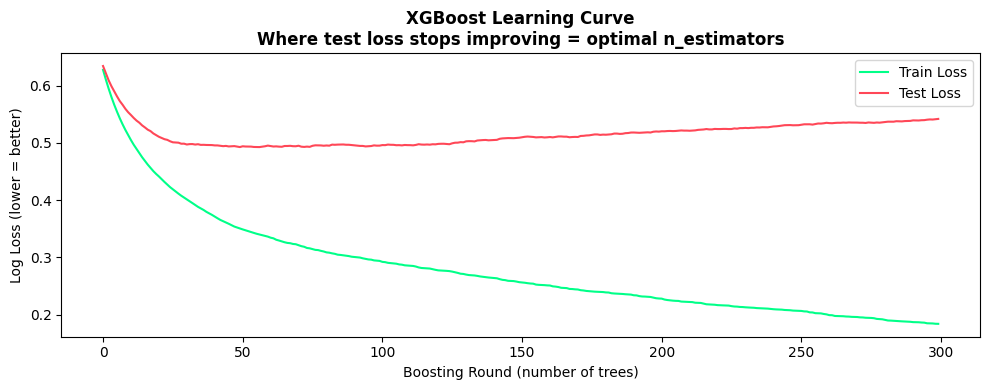

In [22]:
try:
  from xgboost import XGBClassifier
except:
  import subprocess; subprocess.run(["pip",'install','xgboost','-q'])
  from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    use_label_encoder=False,
    eval_metric="logloss",
    random_state=42
)

xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)
y_pred_xgb = xgb.predict(X_test)
y_prob_xgb = xgb.predict_proba(X_test)[:, 1]
accuracy = accuracy_score(y_test, y_pred_xgb)
auc = roc_auc_score(y_test, y_prob_xgb)
print(f"XGBoost: Acc={accuracy:.4f}, AUC={auc:.4f}")

# Learning curve — shows boosting progress
xgb2 = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                     use_label_encoder=False, eval_metric="logloss", random_state=42)
xgb2.fit(X_train, y_train, eval_set=[(X_train,y_train),(X_test,y_test)], verbose=False)
res = xgb2.evals_result()

plt.figure(figsize=(10,4))
plt.plot(res["validation_0"]["logloss"], color="#00ff88", lw=1.5, label="Train Loss")
plt.plot(res["validation_1"]["logloss"], color="#ff4757", lw=1.5, label="Test Loss")
plt.xlabel("Boosting Round (number of trees)")
plt.ylabel("Log Loss (lower = better)")
plt.title("XGBoost Learning Curve\nWhere test loss stops improving = optimal n_estimators", fontweight="bold")
plt.legend(); plt.tight_layout(); plt.show()

###sklearn pipeline

In [23]:
import pickle

print("SKLEARN PIPELINE — The Professional Way")
print("="*45)
print("""
ANALOGY: An assembly line.
  Raw material → Clean → Scale → Predict
  One call to fit(), one call to predict().
  No manual step-by-step. No leakage. Deployable.
""")

# One clean pipeline object
production_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model",  RandomForestClassifier(n_estimators=200, max_depth=7,
                                       random_state=42, n_jobs=-1))
])
production_pipeline.fit(X_train, y_train)

# Predict on a REAL new patient (fictional data)
new_patient = pd.DataFrame([{
    "Pregnancies":3, "Glucose":148, "BloodPressure":72,
    "SkinThickness":35, "Insulin":100, "BMI":33.6,
    "DiabetesPedigreeFunction":0.627, "Age":50
}])
prob = production_pipeline.predict_proba(new_patient)[0][1]
pred = production_pipeline.predict(new_patient)[0]

print(f"New patient result:")
print(f"  Diabetes probability: {prob:.1%}")
print(f"  Prediction:           {'DIABETIC' if pred==1 else 'HEALTHY'}")
print(f"  Confidence:           {'High' if prob>0.7 or prob<0.3 else 'Moderate'}")

# Save and reload
with open("diabetescare_model.pkl","wb") as f: pickle.dump(production_pipeline, f)
with open("diabetescare_model.pkl","rb") as f: loaded = pickle.load(f)
print(f"\nModel saved and reloaded successfully!")
print(f"Anyone can now import this file and get predictions.")

"""
from google.colab import drive
drive.mount('/content/drive')          # authorize when prompted

# now write straight into Drive:
with open("/content/drive/MyDrive/diabetescare_model.pkl", "wb") as f:
    pickle.dump(production_pipeline, f) """

SKLEARN PIPELINE — The Professional Way

ANALOGY: An assembly line.
  Raw material → Clean → Scale → Predict
  One call to fit(), one call to predict().
  No manual step-by-step. No leakage. Deployable.

New patient result:
  Diabetes probability: 52.7%
  Prediction:           DIABETIC
  Confidence:           Moderate

Model saved and reloaded successfully!
Anyone can now import this file and get predictions.


'\nfrom google.colab import drive\ndrive.mount(\'/content/drive\')          # authorize when prompted\n\n# now write straight into Drive:\nwith open("/content/drive/MyDrive/diabetescare_model.pkl", "wb") as f:\n    pickle.dump(production_pipeline, f) '

###Complete model comparison

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

all_models = {
    "Logistic Regression": Pipeline([("sc",StandardScaler()),("m",LogisticRegression(max_iter=1000))]),
    "KNN":                 Pipeline([("sc",StandardScaler()),("m",KNeighborsClassifier(n_neighbors=9))]),
    "Naive Bayes":         GaussianNB(),
    "Decision Tree":       DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42, n_jobs=-1),
    "XGBoost":             XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                                          use_label_encoder=False, eval_metric="logloss", random_state=42),
}

print(f"\n{'Model':<22}{'Acc':>7}{'Prec':>7}{'Rec':>7}{'F1':>7}{'AUC':>7}{'FN':>5}")
print("─"*65)
for name, model in all_models.items():
    model.fit(X_train, y_train)
    yp  = model.predict(X_test)
    ypr = model.predict_proba(X_test)[:,1]
    from sklearn.metrics import confusion_matrix as cm_fn
    tn_,fp_,fn_,tp_ = cm_fn(y_test,yp).ravel()
    print(f"{name:<20}"
          f"{accuracy_score(y_test,yp):>7.3f}"
          f"{precision_score(y_test,yp,zero_division=0):>7.3f}"
          f"{recall_score(y_test,yp,zero_division=0):>7.3f}"
          f"{f1_score(y_test,yp,zero_division=0):>7.3f}"
          f"{roc_auc_score(y_test,ypr):>7.3f}"
          f"{fn_:>5}")

print(f"\n→ For medical use: minimise FN (missed diabetics)!")
print(f"→ Best overall AUC wins for this task.")


Model                     Acc   Prec    Rec     F1    AUC   FN
─────────────────────────────────────────────────────────────────
Logistic Regression   0.708  0.600  0.500  0.545  0.813   27
KNN                   0.740  0.635  0.611  0.623  0.795   21
Naive Bayes           0.701  0.567  0.630  0.596  0.765   20
Decision Tree         0.760  0.639  0.722  0.678  0.762   15
Random Forest         0.753  0.690  0.537  0.604  0.809   25
XGBoost               0.760  0.673  0.611  0.641  0.827   21

→ For medical use: minimise FN (missed diabetics)!
→ Best overall AUC wins for this task.


In [25]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# ypr = XGBoost's predicted probabilities on X_test
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

print(f"{'Threshold':<10}{'FN':>5}{'FP':>6}{'Recall':>8}{'Precision':>11}{'F1':>7}")
print("─" * 50)
for t in thresholds:
    yp_t = (ypr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp_t).ravel()
    print(f"{t:<10}{fn:>5}{fp:>6}"
          f"{recall_score(y_test, yp_t):>8.3f}"
          f"{precision_score(y_test, yp_t, zero_division=0):>11.3f}"
          f"{f1_score(y_test, yp_t, zero_division=0):>7.3f}")

Threshold    FN    FP  Recall  Precision     F1
──────────────────────────────────────────────────
0.5          21    16   0.611      0.673  0.641
0.4          18    21   0.667      0.632  0.649
0.3          11    24   0.796      0.642  0.711
0.2           7    33   0.870      0.588  0.701
0.1           4    42   0.926      0.543  0.685


###Unsupervised Learning

#### K Means Clustering

Notice: we generated this data with 4 TRUE hidden groups.

K-Means doesnt know this -- let's see if it can FIND them.



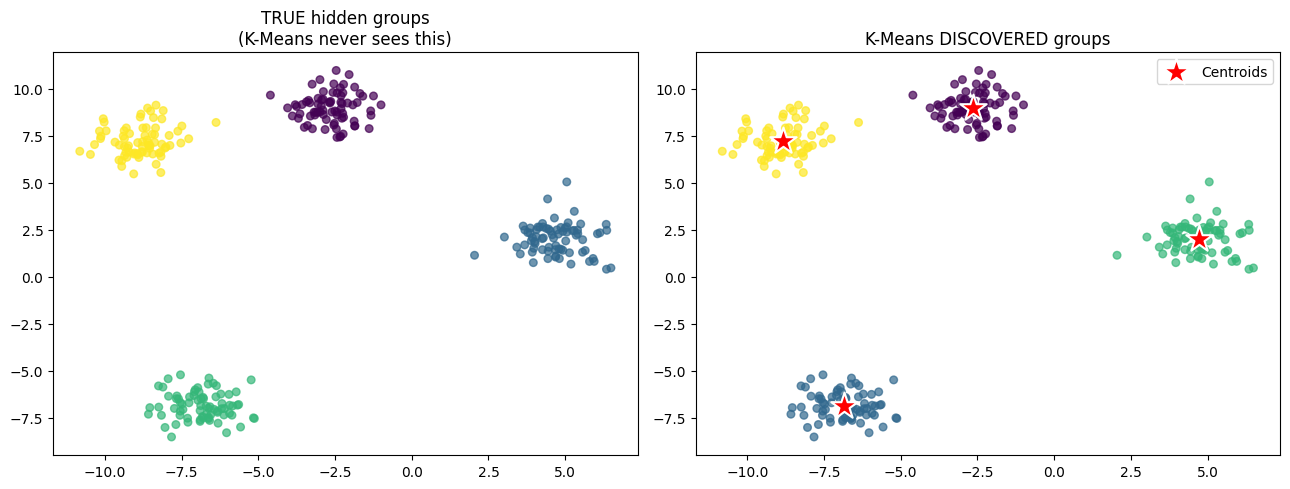

K-Means found the groups almost perfectly , Without ever
being told the true labels. This is the power of clustering.


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs

#Start simple --  create synthetic data with 4 clear natural groups
X_demo, y_true = make_blobs(n_samples=300, centers=4,
                            cluster_std=0.8, random_state=42)

print("Notice: we generated this data with 4 TRUE hidden groups.\n")
print("K-Means doesnt know this -- let's see if it can FIND them.\n")

km = KMeans(n_clusters = 4, random_state = 42, n_init =10)
labels = km.fit_predict(X_demo)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_demo[:,0], X_demo[:,1], c=y_true, cmap="viridis", s=30, alpha=0.7)
axes[0].set_title("TRUE hidden groups\n(K-Means never sees this)")

axes[1].scatter(X_demo[:,0], X_demo[:,1], c=labels, cmap="viridis", s=30, alpha=0.7)
axes[1].scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1],
                marker="*", s=400, c="red", edgecolor="white", linewidth=1.5,
                label="Centroids")
axes[1].set_title("K-Means DISCOVERED groups")
axes[1].legend()
plt.tight_layout(); plt.show()

print(f'K-Means found the groups almost perfectly , Without ever')
print(f'being told the true labels. This is the power of clustering.')

####Elbow Method

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

<Figure size 900x500 with 0 Axes>

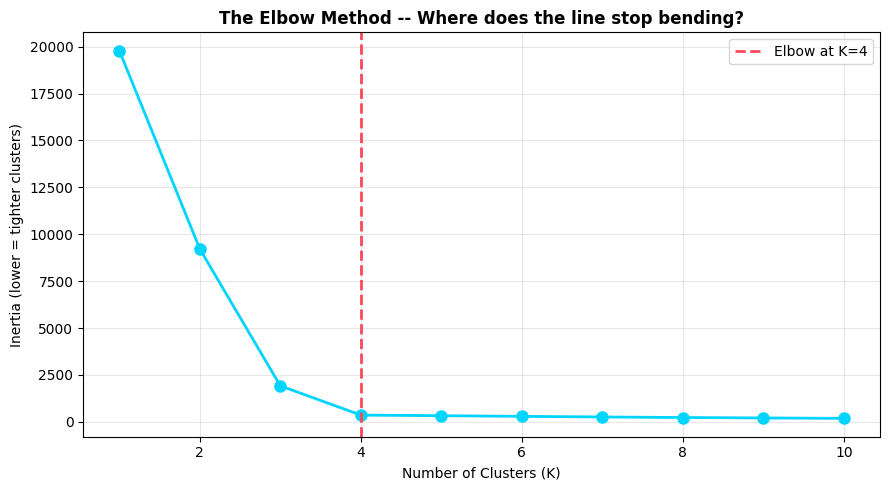

Inertia Values by k:
 K=1: inertia:19780.3
 K=2: inertia:9211.2
 K=3: inertia:1919.4
 K=4: inertia:362.5
 K=5: inertia:329.3
 K=6: inertia:294.6
 K=7: inertia:261.6
 K=8: inertia:232.0
 K=9: inertia:209.1
 K=10: inertia:188.7

Notice: inertia ALWAYS decreases as K incrases (more groups = tighter fit)
We look for the 'elbow' -- where adding more clusters stops giving
meaningful improvemnet. Here thats clearly k =4


In [2]:
#Finding the optimal k values -- Using Elbow Method
inertias = []
k_range   = range(1,11)

for k in k_range:
  km_test   =   KMeans(n_clusters=k, random_state=42,n_init=10)
  km_test.fit(X_demo)
  inertias.append(km_test.inertia_)  #inertia = sum of squared distances to centroid

  plt.figure(figsize=(9, 5))
plt.plot(k_range, inertias, "o-", color="#00d4ff", linewidth=2, markersize=8)
plt.axvline(4, color="#ff4757", linestyle="--", linewidth=2, label="Elbow at K=4")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (lower = tighter clusters)")
plt.title("The Elbow Method -- Where does the line stop bending?", fontweight="bold")
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

print("Inertia Values by k:")
for k,i in zip(k_range,inertias):
  print(f" K={k}: inertia:{i:.1f}")

print(f"\nNotice: inertia ALWAYS decreases as K incrases (more groups = tighter fit)")
print(f"We look for the 'elbow' -- where adding more clusters stops giving")
print(f"meaningful improvemnet. Here thats clearly k =4")

###Real Custometer segmentation

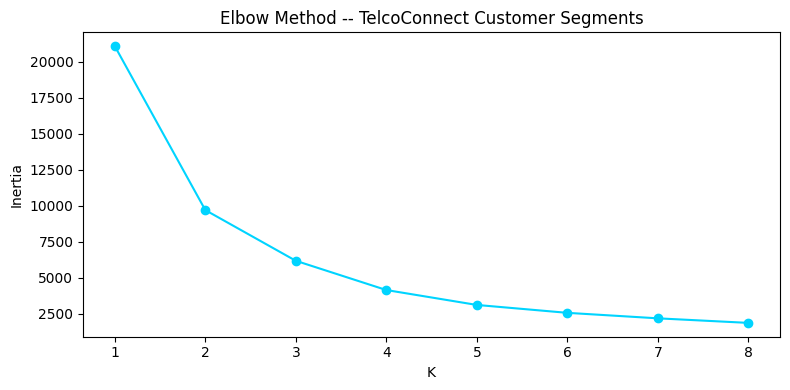

Segment profile (average values per group):
         tenure  MonthlyCharges  TotalCharges  Count  Churn_Rate
Segment                                                         
0          10.3            31.8         303.8   1696       0.248
1          59.5            93.3        5548.7   1904       0.154
2          53.6            34.9        1836.6   1159       0.050
3          15.4            80.8        1252.8   2273       0.483

 Business interpretation
Look at the each segments tenure, spending, and churn rate
which segment looks like 'new customers as risk
WHich looks like 'loya high-value customers


In [3]:
# Apply to REAL  business data - Telco customer segmentation
url = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(url)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dropna(subset = ['TotalCharges'], inplace = True)

#Segment customers by: tenure, monthly charges, total charges
seg_features = df[["tenure","MonthlyCharges","TotalCharges"]]
scaler    =  StandardScaler()
seg_scaled  = scaler.fit_transform(seg_features)

#Find best k for THIS real data
inertias = []
for k in range(1,9):
  km_test= KMeans(n_clusters=k, random_state=42,n_init=10)
  km_test.fit(seg_scaled)
  inertias.append(km_test.inertia_)

plt.figure(figsize=(8,4))
plt.plot(range(1,9), inertias, "o-", color="#00d4ff")
plt.xlabel("K")
plt.ylabel("Inertia")
plt.title("Elbow Method -- TelcoConnect Customer Segments")
plt.tight_layout()
plt.show()



# Apply K=4 (a reasonable business choice: e.g .new/loyal/big-spender/at-risk)
km_final = KMeans(n_clusters =4 , random_state = 42, n_init=10)
df["Segment"] = km_final.fit_predict(seg_scaled)

print("Segment profile (average values per group):")
profile = df.groupby("Segment")[["tenure","MonthlyCharges","TotalCharges"]].mean().round(1)
profile["Count"] = df["Segment"].value_counts().sort_index()
profile["Churn_Rate"] = df.groupby("Segment")["Churn"].apply(lambda x:(x=="Yes").mean()).round(3)
print(profile)

print(f"\n Business interpretation")
print(f"Look at the each segments tenure, spending, and churn rate")
print(f"which segment looks like 'new customers as risk")
print(f"WHich looks like 'loya high-value customers")

###DB SCAN

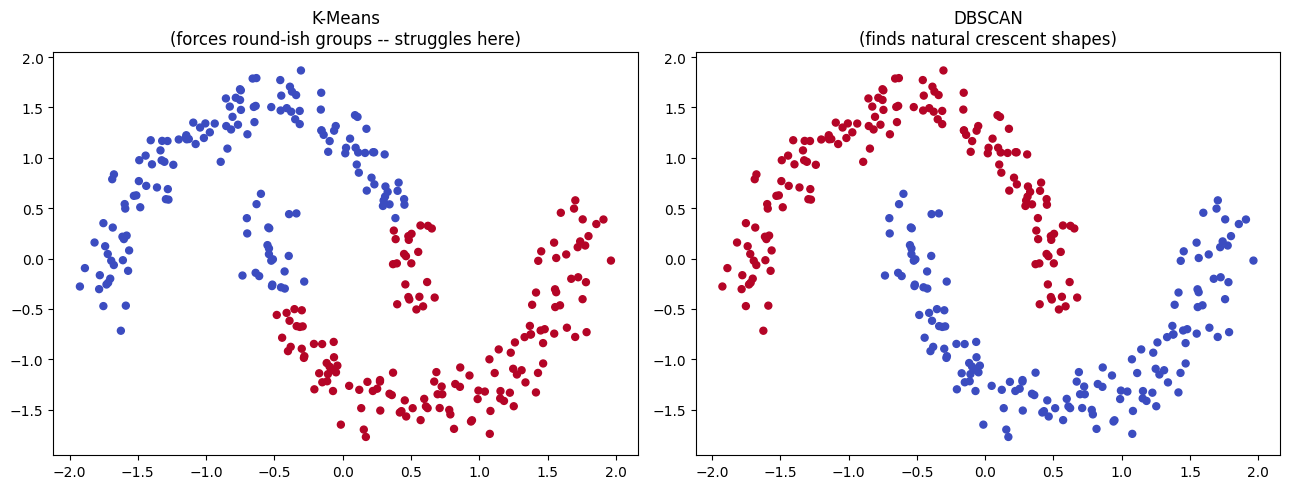

DBSCAN found2 clusters and 0 noise points
K-Means was FORCED to draw a straight-ish line through the cresents
Incooreclty splitting the natural corved groups


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

# DBSCAN shines on non-round shapes -- K-Means fails here
X_moons, _ = make_moons(n_samples=300, noise=0.08, random_state=42)
X_scaled   = StandardScaler().fit_transform(X_moons)

# Try K-Means (will struggle with this crescent shape)
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = km.fit_predict(X_scaled)

# Try DBSCAN (should handle the crescents naturally)
db = DBSCAN(eps=0.3, min_samples=5)
db_labels = db.fit_predict(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_scaled[:,0], X_scaled[:,1], c=km_labels, cmap="coolwarm", s=25)
axes[0].set_title("K-Means\n(forces round-ish groups -- struggles here)")

axes[1].scatter(X_scaled[:,0], X_scaled[:,1], c=db_labels, cmap="coolwarm", s=25)
axes[1].set_title("DBSCAN\n(finds natural crescent shapes)")
plt.tight_layout(); plt.show()

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = list(db_labels).count(-1)
print(f"DBSCAN found{n_clusters_db} clusters and {n_noise} noise points")
print(f"K-Means was FORCED to draw a straight-ish line through the cresents")
print(f"Incooreclty splitting the natural corved groups")

### DBSCAN Parameters Effect

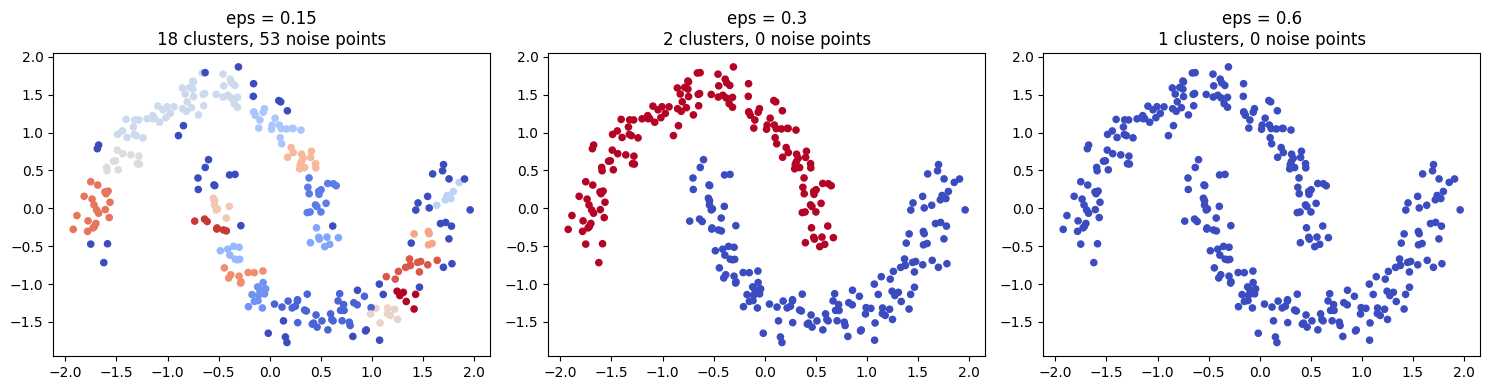


eps TOO small - Everything looks like noise(points seem far apart)
eps TOO LARGE - Everything merges into ONE giant cluster
eps JUST RIGHT - clean, natural groups + genuine outliers flagged

choosing eps is somewhat trial - and - error - plot a "k-distance graph"
(distancr to  kth nearest neighbour, sorted) and look for an elbow,
similar to K-means elbow method



In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, eps_val in zip(axes, [0.15, 0.3, 0.6]):
    db_test = DBSCAN(eps=eps_val, min_samples=5)
    labels  = db_test.fit_predict(X_scaled)
    n_clust = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    ax.scatter(X_scaled[:,0], X_scaled[:,1], c=labels, cmap="coolwarm", s=20)
    ax.set_title(f"eps = {eps_val}\n{n_clust} clusters, {n_noise} noise points")

plt.tight_layout()
plt.show()

print("""
eps TOO small - Everything looks like noise(points seem far apart)
eps TOO LARGE - Everything merges into ONE giant cluster
eps JUST RIGHT - clean, natural groups + genuine outliers flagged

choosing eps is somewhat trial - and - error - plot a "k-distance graph"
(distancr to  kth nearest neighbour, sorted) and look for an elbow,
similar to K-means elbow method
""")

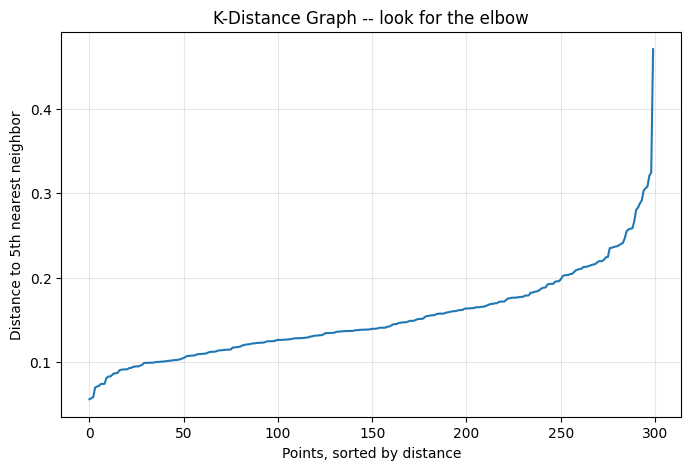

In [15]:
from sklearn.neighbors import NearestNeighbors

min_samples = 5  # match whatever you're using in DBSCAN

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Distance to the k-th (last) nearest neighbor, sorted ascending
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist)
plt.xlabel("Points, sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("K-Distance Graph -- look for the elbow")
plt.grid(True, alpha=0.3)
plt.show()

### Isolation Forest

In [18]:
from sklearn.ensemble import IsolationForest

#Simulate credit-card-like transaction
np.random.seed(42)
n_normal, n_fraud = 980,20    #2% fraud rate -- realistic imbalance

X_normal = np.random.randn(n_normal,4)  * [50,10,2,100] + [200,30,1,500]
X_fraud =  np.random.randn(n_fraud,4) * [200,50,5,400] + [800,80,8,2000]

X_trans = np.vstack([X_normal,X_fraud])
y_true = np.array([0]*n_normal + [1]*n_fraud)   #0=normal,1=fraud (for evaluation only!)

print(f"Total transactions :  {len(X_trans)}")
print(f"True fraud count: {y_true.sum()} ({y_true.mean():.1%})")
print(f"\nNote: Isolation Forest does NOT use y_true during training --")
print(f"it only learns what 'normal' data looks like.")

iso_forest = IsolationForest(contamination = 0.02 ,random_state = 42, n_estimators = 100)        # our estimate of fraud rate  - contamination

prediction = iso_forest.fit_predict(X_trans)              # returns 1 = normal , -1 = anomaly
anomaly_scores = iso_forest.score_samples(X_trans)        # lower = more anomalus

# Convert to match our labels (1 =fraud like y_true)
pred_fraud = (prediction == -1).astype(int)

from sklearn.metrics import classification_report, confusion_matrix
print(f"\nIsolation Forest Results:")
print(classification_report(y_true, pred_fraud, target_names = ["Normal","Fraud"]))
print(f"COnfusion Matrix:\n{confusion_matrix(y_true , pred_fraud)}")

Total transactions :  1000
True fraud count: 20 (2.0%)

Note: Isolation Forest does NOT use y_true during training --
it only learns what 'normal' data looks like.

Isolation Forest Results:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       980
       Fraud       1.00      1.00      1.00        20

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

COnfusion Matrix:
[[980   0]
 [  0  20]]


###Complete fraud detection pipeline

TOP 10 MOST SUSPICIOUS TRANSACTIONS (for analyst review):
 Amount  Frequency  Locations  AvgTicket  Anomaly_Score  Flagged_Fraud  Actually_Fraud
1072.51     162.03      23.76    1550.60          -0.82              1               1
1203.06     144.53       6.01    1559.09          -0.79              1               1
 901.25     152.37      10.84    1580.14          -0.79              1               1
 653.67     174.52       8.25    2307.54          -0.79              1               1
 717.56     125.67      10.69    2171.27          -0.78              1               1
 977.50     118.04       8.30    2155.32          -0.78              1               1
 564.13      88.61      11.36    2611.21          -0.78              1               1
 781.41      68.02      13.58    2074.57          -0.77              1               1
1236.82     108.53       5.10    1755.45          -0.77              1               1
 747.47      63.18      12.80    2184.99          -0.77              1  

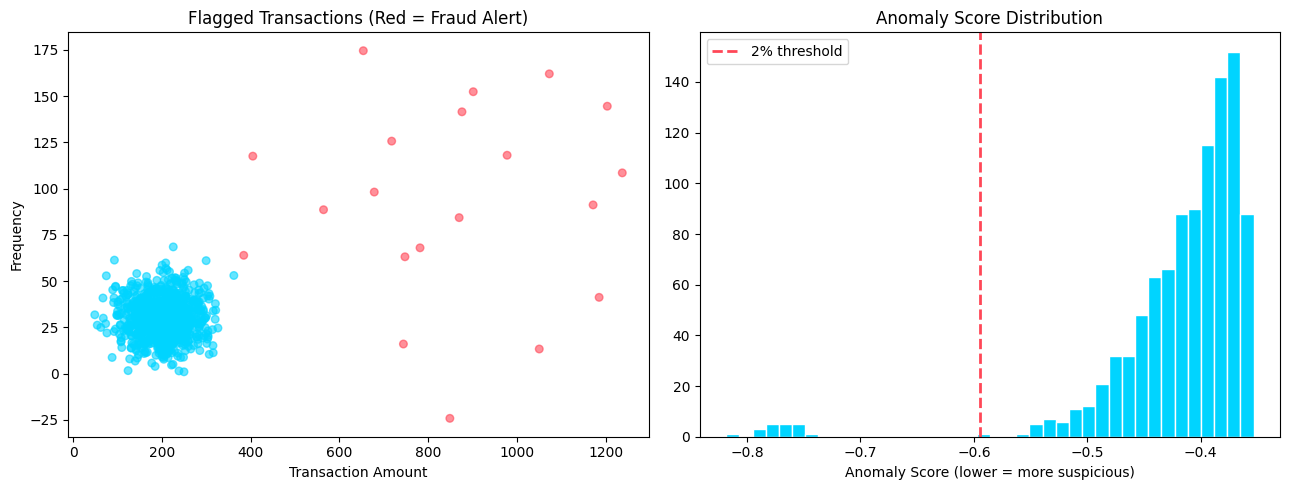


In production, the fraud team would review the TOP flagged
transactions first, prioritising limited investigator time
on the Most anomalous cases.


In [22]:
import pandas as pd

#Build a readable fraud investiation report
df_trans = pd.DataFrame(X_trans,columns=["Amount","Frequency","Locations","AvgTicket"])
df_trans["Anomaly_Score"] = anomaly_scores
df_trans["Flagged_Fraud"] = pred_fraud
df_trans["Actually_Fraud"]  = y_true

#Sort by most anomalous first -- this is what fraud analsyt would review
top_suspicious  = df_trans.sort_values("Anomaly_Score").head(10)
print("TOP 10 MOST SUSPICIOUS TRANSACTIONS (for analyst review):")
print(top_suspicious.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#ff4757" if f==1 else "#00d4ff" for f in pred_fraud]
axes[0].scatter(df_trans["Amount"], df_trans["Frequency"], c=colors, alpha=0.6, s=30)
axes[0].set_xlabel("Transaction Amount"); axes[0].set_ylabel("Frequency")
axes[0].set_title("Flagged Transactions (Red = Fraud Alert)")

axes[1].hist(anomaly_scores, bins=40, color="#00d4ff", edgecolor="white")
threshold = np.percentile(anomaly_scores, 2)
axes[1].axvline(threshold, color="#ff4757", linestyle="--", linewidth=2,
                label=f"2% threshold")
axes[1].set_title("Anomaly Score Distribution")
axes[1].set_xlabel("Anomaly Score (lower = more suspicious)")
axes[1].legend()
plt.tight_layout(); plt.show()

print(f"\nIn production, the fraud team would review the TOP flagged")
print(f"transactions first, prioritising limited investigator time")
print(f"on the Most anomalous cases.")